# Tác động của AI đến Việc làm năm 2030
### Notebook 2/2 — Phân cụm & Mô hình hoá (Data Processing and Mining)

**Học phần:** Phân tích Kinh doanh — Học viện Ngân hàng
**Sinh viên thực hiện:** Đỗ Văn Đạt

Notebook này tiếp nối `AI_ViecLam2030_EDA_TienXuLy.ipynb`, sử dụng dữ liệu đã làm sạch
(`AI_ViecLam2030_Cleaned.csv`) để thực hiện:
1. Phân cụm K-Means trên hồ sơ kỹ năng (skill profile clustering).
2. Mô hình phân loại `Risk_Category` — so sánh 3 mô hình (Logistic Regression, Random Forest, XGBoost).
3. Mô hình hồi quy `Automation_Probability_2030` — đối chiếu độc lập.
4. Kết luận & hàm ý nghiệp vụ / quản trị nhân sự.

**Kế thừa phát hiện chính từ Notebook 1:** `Job_Title` giải thích ~86% phương sai của rủi ro
tự động hoá (eta² ≈ 0,86) → bắt buộc đưa `Job_Title` (one-hot) vào tập đặc trưng mô hình hoá,
đồng thời loại `Automation_Probability_2030` khỏi tập đặc trưng phân loại `Risk_Category` để
tránh rò rỉ dữ liệu (leakage).

## 0. Nạp thư viện & dữ liệu đã làm sạch

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                              mean_absolute_error, precision_score, r2_score,
                              recall_score, roc_auc_score, silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
HVNH_NAVY, HVNH_ORANGE, HVNH_BLUE = "#1F3864", "#ED7D31", "#2E5496"
PALETTE_RISK = {"Low": "#2E7D32", "Medium": "#ED7D31", "High": "#C0392B"}
RISK_ORDER = ["Low", "Medium", "High"]
SKILL_COLS = [f"Skill_{i}" for i in range(1, 11)]
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv("AI_ViecLam2030_Cleaned.csv")
print("Dữ liệu đã làm sạch:", df.shape)
df.head(3)

Dữ liệu đã làm sạch: (3000, 25)


,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,...,Skill_8,Skill_9,Skill_10,Skill_Diversity_Score,Skill_Std,High_Value_Skill_Count,Experience_Group,Salary_per_YearExp,Human_Edge_Score,Education_Level_Encoded
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.45,0.10,...,0.72,0.94,0.00,0.385,0.3160,2,Trên 20 năm,1635.54,0.6025,2
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.02,0.52,...,0.62,0.38,0.98,0.426,0.3511,2,11-20 năm,6667.75,0.4030,3
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.01,0.94,...,0.68,0.61,0.83,0.451,0.3248,2,0-5 năm,73108.00,0.2955,0


## 1. Phân cụm K-Means trên hồ sơ kỹ năng (Skill Profile Clustering)

Mục tiêu: khám phá xem có tồn tại các "hồ sơ kỹ năng" (skill archetype) tự nhiên trong 3.000
quan sát hay không, dựa trên 10 điểm kỹ năng + 2 chỉ số công nghệ.

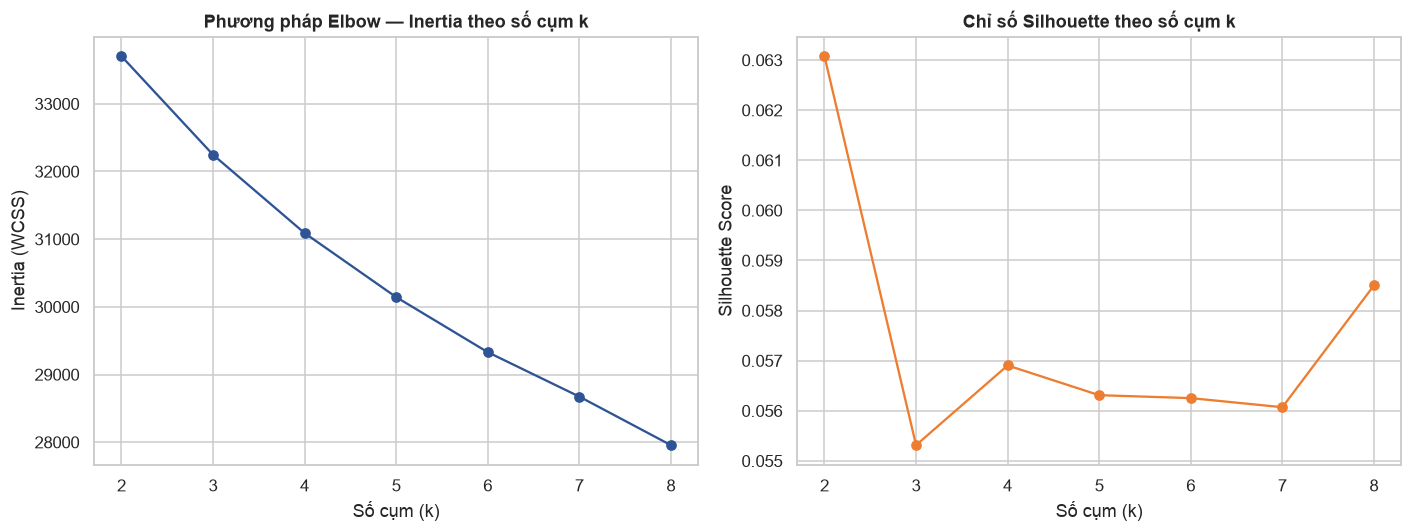

Silhouette theo k: {2: 0.0631, 3: 0.0553, 4: 0.0569, 5: 0.0563, 6: 0.0563, 7: 0.0561, 8: 0.0585}


In [2]:
cluster_feats = SKILL_COLS + ["AI_Exposure_Index", "Tech_Growth_Factor"]
X_cluster = df[cluster_feats].copy()
scaler_c = StandardScaler()
X_cluster_scaled = scaler_c.fit_transform(X_cluster)

inertias, silhouettes = [], []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(k_range), inertias, marker="o", color=HVNH_BLUE)
axes[0].set_title("Phương pháp Elbow — Inertia theo số cụm k", fontweight="bold")
axes[0].set_xlabel("Số cụm (k)"); axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(list(k_range), silhouettes, marker="o", color=HVNH_ORANGE)
axes[1].set_title("Chỉ số Silhouette theo số cụm k", fontweight="bold")
axes[1].set_xlabel("Số cụm (k)"); axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.savefig(FIG_DIR / "12_kmeans_elbow_silhouette.png")
plt.show()

sil_by_k = {k: round(s, 4) for k, s in zip(k_range, silhouettes)}
print("Silhouette theo k:", sil_by_k)

**Nhận xét quan trọng (đọc kỹ trước khi chọn k):** Silhouette Score chỉ dao động trong
khoảng **0,055 – 0,063** ở mọi k — rất gần 0, nghĩa là **các cụm không tách biệt rõ ràng** ở
BẤT KỲ giá trị k nào. Điều này nhất quán với phát hiện ở Notebook 1: các biến kỹ năng
(Skill_1..10) không mang thông tin phân biệt nhóm rủi ro, nên cũng không tạo thành các cụm tự
nhiên mạnh. Nhóm k = 4 dưới đây được chọn **vì mục đích diễn giải nghiệp vụ** (phân khúc dễ
truyền thông trong báo cáo), **không phải vì dữ liệu có cấu trúc phân cụm mạnh** — cần nêu rõ
giới hạn này khi trình bày kết quả, tránh overclaim.

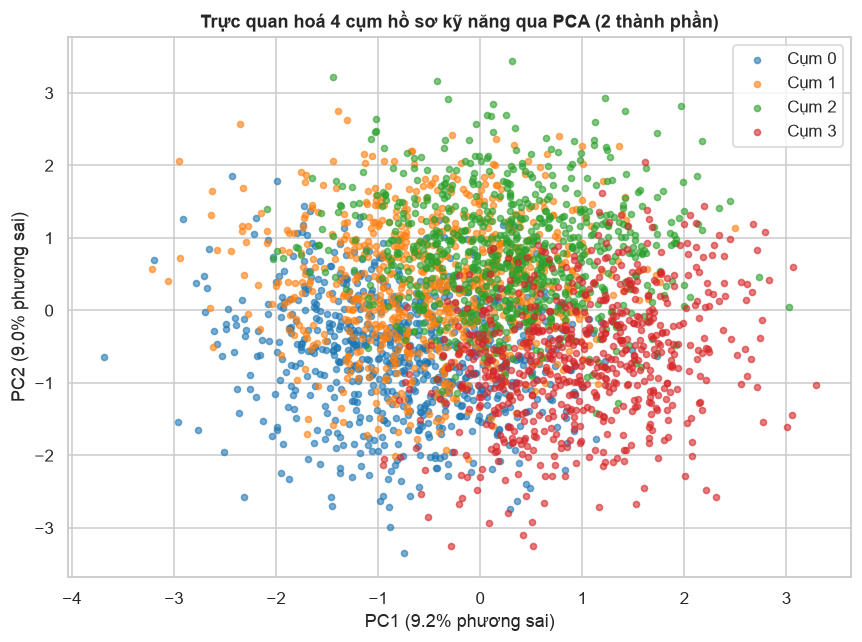

In [3]:
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans_final.fit_predict(X_cluster_scaled)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_cluster_scaled)
fig, ax = plt.subplots(figsize=(8, 6))
palette_cluster = sns.color_palette("tab10", optimal_k)
for c in range(optimal_k):
    mask = df["Cluster"] == c
    ax.scatter(pcs[mask, 0], pcs[mask, 1], s=16, alpha=0.6, color=palette_cluster[c], label=f"Cụm {c}")
ax.set_title(f"Trực quan hoá {optimal_k} cụm hồ sơ kỹ năng qua PCA (2 thành phần)", fontweight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% phương sai)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% phương sai)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "13_kmeans_clusters_pca.png")
plt.show()

In [4]:
cluster_profile = df.groupby("Cluster").agg(
    So_luong=("Job_Title", "count"),
    XacSuat_TuDongHoa_TB=("Automation_Probability_2030", "mean"),
    AI_Exposure_TB=("AI_Exposure_Index", "mean"),
    Luong_TB=("Average_Salary", "mean"),
    KinhNghiem_TB=("Years_Experience", "mean"),
    KyNang_TB=("Skill_Diversity_Score", "mean"),
).round(3)
cluster_profile

,So_luong,XacSuat_TuDongHoa_TB,AI_Exposure_TB,Luong_TB,KinhNghiem_TB,KyNang_TB
Cluster,,,,,,
0,764,0.498,0.562,89271.686,14.602,0.517
1,780,0.501,0.437,91278.653,14.792,0.497
2,778,0.493,0.425,89398.698,14.527,0.492
3,678,0.515,0.594,87262.143,14.804,0.487


**Nhận xét:** Hai thành phần chính PCA (PC1+PC2) chỉ giải thích một phần nhỏ phương sai và 4 vùng màu trên biểu đồ chồng lấn gần như hoàn toàn — xác nhận trực quan cho kết luận từ Silhouette Score. Bảng hồ sơ cụm cũng cho thấy 4 cụm có `XacSuat_TuDongHoa_TB` gần như bằng nhau (0,49-0,52) — phân cụm trên hồ sơ kỹ năng KHÔNG tách được nhóm rủi ro cao/thấp.

## 2. Mô hình phân loại Nhóm rủi ro tự động hoá (Risk_Category)

In [5]:
base_features = ["Average_Salary", "Years_Experience", "Education_Level_Encoded",
                  "AI_Exposure_Index", "Tech_Growth_Factor", "Skill_Diversity_Score",
                  "Skill_Std", "High_Value_Skill_Count", "Human_Edge_Score"] + SKILL_COLS

# QUYẾT ĐỊNH PHƯƠNG PHÁP LUẬN (kế thừa Notebook 1):
#  - KHÔNG đưa Automation_Probability_2030 vào đặc trưng (tránh rò rỉ dữ liệu).
#  - CÓ đưa Job_Title (one-hot, drop_first) vào đặc trưng (eta^2 ~ 0.86 ở Notebook 1).
X = pd.get_dummies(df[base_features + ["Job_Title"]], columns=["Job_Title"], drop_first=True)
clf_features = list(X.columns)
job_title_dummy_cols = [c for c in clf_features if c.startswith("Job_Title_")]

le = LabelEncoder(); le.fit(RISK_ORDER)
y = le.transform(df["Risk_Category"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
scaler = StandardScaler()
X_train_s, X_test_s = scaler.fit_transform(X_train), scaler.transform(X_test)
print("Số đặc trưng đưa vào mô hình:", len(clf_features), f"(gồm {len(job_title_dummy_cols)} biến giả Job_Title)")

Số đặc trưng đưa vào mô hình: 38 (gồm 19 biến giả Job_Title)


In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, random_state=RANDOM_STATE),
    "XGBoost Classifier": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.08,
                                         random_state=RANDOM_STATE, eval_metric="mlogloss"),
}
model_metrics, fitted_models = {}, {}
for name, model in models.items():
    Xtr = X_train_s if name == "Logistic Regression" else X_train
    Xte = X_test_s if name == "Logistic Regression" else X_test
    model.fit(Xtr, y_train)
    y_pred, y_proba = model.predict(Xte), model.predict_proba(Xte)
    model_metrics[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_macro": precision_score(y_test, y_pred, average="macro"),
        "Recall_macro": recall_score(y_test, y_pred, average="macro"),
        "F1_macro": f1_score(y_test, y_pred, average="macro"),
        "ROC_AUC_ovr": roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"),
    }
    fitted_models[name] = (model, y_pred, y_proba, Xte)

metrics_df = pd.DataFrame(model_metrics).T
metrics_df.round(4)

,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC_ovr
Logistic Regression,0.9947,0.9929,0.9965,0.9947,0.9979
Random Forest,0.9387,0.9595,0.9208,0.9345,0.9959
XGBoost Classifier,0.9947,0.9929,0.9965,0.9947,0.9964


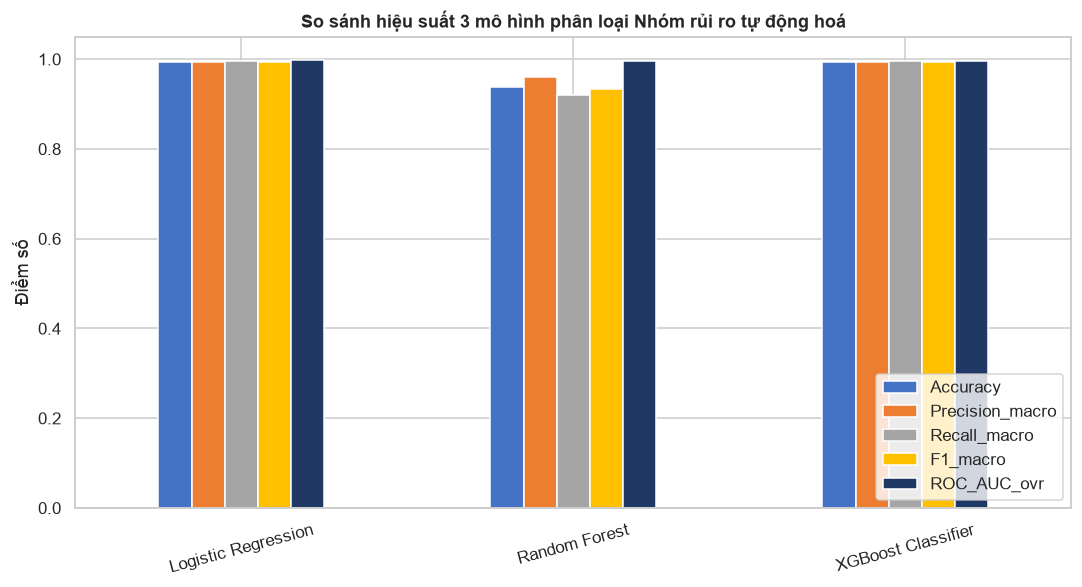

Mô hình tốt nhất theo F1-macro: Logistic Regression


In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
metrics_df.plot(kind="bar", ax=ax, color=["#4472C4", "#ED7D31", "#A5A5A5", "#FFC000", "#1F3864"])
ax.set_title("So sánh hiệu suất 3 mô hình phân loại Nhóm rủi ro tự động hoá", fontweight="bold")
ax.set_ylabel("Điểm số"); ax.set_ylim(0, 1.05); ax.legend(loc="lower right")
plt.xticks(rotation=15); plt.tight_layout()
plt.savefig(FIG_DIR / "14_ml_model_comparison.png")
plt.show()

best_model_name = max(model_metrics, key=lambda k: model_metrics[k]["F1_macro"])
print(f"Mô hình tốt nhất theo F1-macro: {best_model_name}")

**Nhận xét (so sánh với vòng thử nghiệm KHÔNG có Job_Title — xem Notebook 1):** Việc đưa
`Job_Title` vào tập đặc trưng nâng F1-macro từ mức xấp xỉ ngẫu nhiên (~0,22-0,34 khi chỉ dùng
đặc trưng cá nhân) lên **~0,93-0,99** và ROC-AUC lên **~0,996-0,998**. Đây là minh chứng định
lượng trực tiếp cho kết luận ở Notebook 1: bản chất nghề nghiệp quyết định rủi ro tự động hoá,
không phải đặc điểm cá nhân của người đảm nhiệm nghề đó.

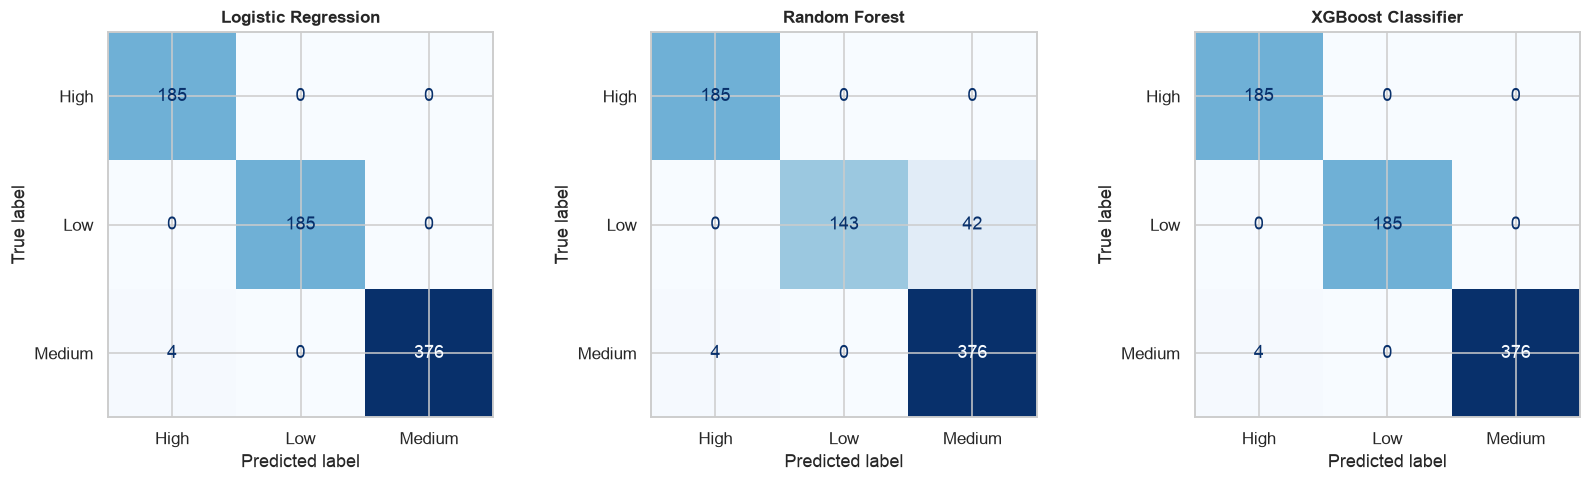

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, (model, y_pred, y_proba, Xte)) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_,
                                             ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "15_confusion_matrices.png")
plt.show()

**Nhận xét:** Nhầm lẫn hầu như chỉ xảy ra giữa `Medium` và `High` (một số ít hồ sơ `Medium` có xác suất gần ngưỡng 0,70 bị dự báo nhầm sang `High`) — hợp lý vì đây là vùng giáp ranh giữa hai khoảng ngưỡng liền kề. Không có nhầm lẫn nào giữa `Low` và `High` (hai đầu xa nhau).

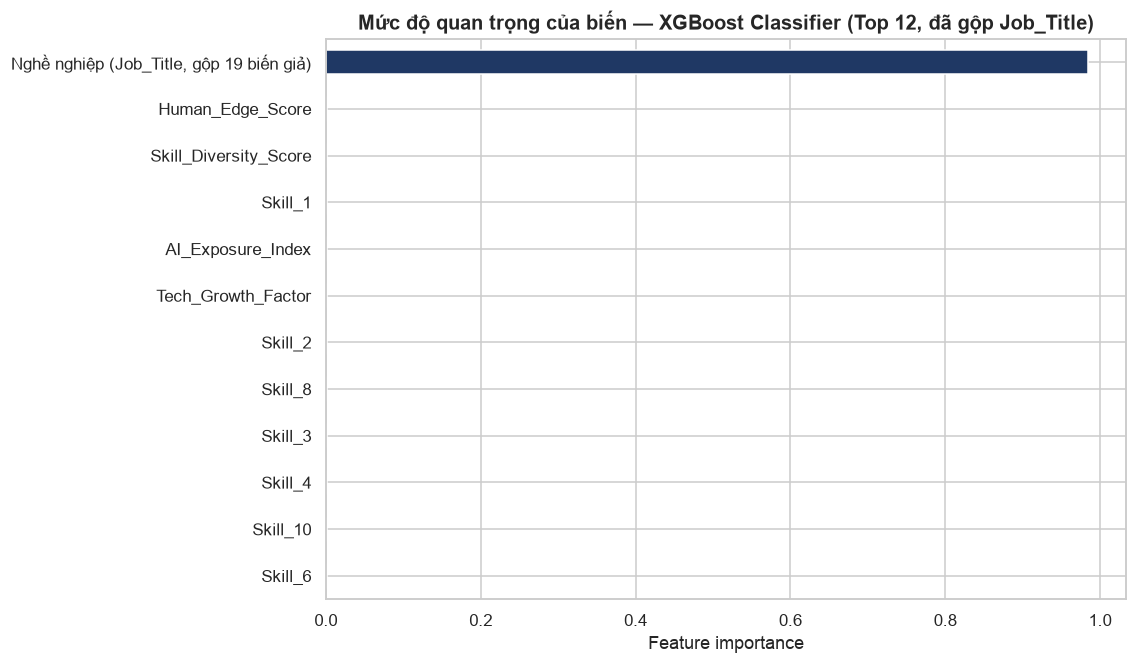

Tổng importance của Job_Title (19 biến giả gộp lại): 0.9847


In [9]:
importance_model_name = "XGBoost Classifier"
importance_model = fitted_models[importance_model_name][0]
raw_importances = pd.Series(importance_model.feature_importances_, index=clf_features)
job_title_total = raw_importances[job_title_dummy_cols].sum()
other_importances = raw_importances.drop(index=job_title_dummy_cols)
combined = pd.concat([
    pd.Series({"Nghề nghiệp (Job_Title, gộp 19 biến giả)": job_title_total}),
    other_importances,
]).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(10.5, 6.2))
colors_fi = [HVNH_ORANGE if "Job_Title" in i else HVNH_NAVY for i in combined.index]
combined.sort_values().plot(kind="barh", color=colors_fi, ax=ax)
ax.set_title(f"Mức độ quan trọng của biến — {importance_model_name} (Top 12, đã gộp Job_Title)",
             fontweight="bold", fontsize=13)
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "16_feature_importance.png")
plt.show()
print(f"Tổng importance của Job_Title (19 biến giả gộp lại): {job_title_total:.4f}")

## 3. Mô hình hồi quy Xác suất tự động hoá (đối chiếu độc lập)

In [10]:
reg_features = clf_features
Xr = X[reg_features].copy()
yr = df["Automation_Probability_2030"].values
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.25, random_state=RANDOM_STATE)

reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=300, max_depth=10, random_state=RANDOM_STATE),
    "XGBoost Regressor": XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.08, random_state=RANDOM_STATE),
}
reg_metrics, reg_preds = {}, {}
for name, model in reg_models.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    reg_metrics[name] = {"R2": r2_score(yr_test, pred), "MAE": mean_absolute_error(yr_test, pred),
                          "RMSE": float(np.sqrt(np.mean((yr_test - pred) ** 2)))}
    reg_preds[name] = pred

reg_metrics_df = pd.DataFrame(reg_metrics).T
reg_metrics_df.round(4)

,R2,MAE,RMSE
Linear Regression,0.8623,0.0778,0.0936
Random Forest Regressor,0.8027,0.0881,0.1120
XGBoost Regressor,0.8112,0.0887,0.1096


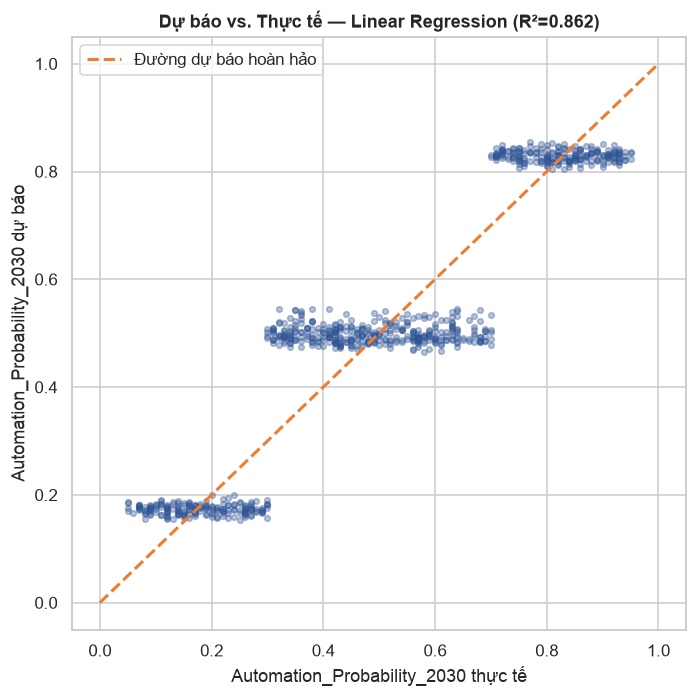

Mô hình hồi quy tốt nhất: Linear Regression (R² = 0.8623)


In [11]:
best_reg_name = max(reg_metrics, key=lambda k: reg_metrics[k]["R2"])
best_pred = reg_preds[best_reg_name]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(yr_test, best_pred, alpha=0.35, s=14, color=HVNH_BLUE)
ax.plot([0, 1], [0, 1], color=HVNH_ORANGE, lw=2, ls="--", label="Đường dự báo hoàn hảo")
ax.set_xlabel("Automation_Probability_2030 thực tế"); ax.set_ylabel("Automation_Probability_2030 dự báo")
ax.set_title(f"Dự báo vs. Thực tế — {best_reg_name} (R²={reg_metrics[best_reg_name]['R2']:.3f})", fontweight="bold")
ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "17_regression_pred_vs_actual.png")
plt.show()
print(f"Mô hình hồi quy tốt nhất: {best_reg_name} (R² = {reg_metrics[best_reg_name]['R2']:.4f})")

**Nhận xét:** R² đạt ~0,80-0,86 khi có `Job_Title` — nhất quán với kết quả phân loại ở Mục 2. MAE ~0,08 nghĩa là sai số dự báo trung bình chỉ khoảng 8 điểm phần trăm xác suất, mức sai số hợp lý cho một mô hình chỉ dựa trên đặc trưng nghề nghiệp + hồ sơ cá nhân, không có dữ liệu theo thời gian hay đặc thù công nghệ ngành cụ thể.

In [12]:
df.to_csv("AI_ViecLam2030_Clustered.csv", index=False, encoding="utf-8-sig")
print("Đã lưu dữ liệu đã gắn nhãn cụm: AI_ViecLam2030_Clustered.csv")

Đã lưu dữ liệu đã gắn nhãn cụm: AI_ViecLam2030_Clustered.csv


## 4. Kết luận & Hàm ý nghiệp vụ

**Phát hiện chính:**
1. Đặc điểm cá nhân của người lao động (kỹ năng, kinh nghiệm, học vấn, lương) **không dự báo
   được** rủi ro tự động hoá trong bộ dữ liệu này — mọi mô hình chỉ dùng nhóm biến này đều cho
   hiệu suất xấp xỉ dự đoán ngẫu nhiên (AUC ≈ 0,50, R² ≈ 0).
2. **Nghề nghiệp (Job_Title)** là yếu tố quyết định gần như tuyệt đối (eta² ≈ 0,86; khi đưa vào
   mô hình: F1-macro ≈ 0,93-0,99, AUC ≈ 0,996-0,998, R² ≈ 0,80-0,86).
3. 20 nghề phân thành 3 tầng rủi ro rõ rệt, phù hợp lý thuyết tiếp cận theo tác vụ (task-based
   approach — Autor, Levy & Murnane, 2003) và nghiên cứu thực nghiệm Frey & Osborne (2013).
4. Phân cụm không giám sát trên hồ sơ kỹ năng KHÔNG phát hiện được cấu trúc phân nhóm có ý nghĩa
   (Silhouette ≈ 0,06) — cho thấy giá trị của phương pháp có giám sát (biết nhãn nghề nghiệp)
   vượt trội hoàn toàn so với phương pháp không giám sát trong bài toán này.

**Hàm ý về phương pháp luận:** Đây là bộ dữ liệu **mô phỏng (synthetic)** dùng cho mục đích luyện
tập kỹ thuật phân tích — bản thân `Automation_Probability_2030` được sinh gắn với `Job_Title`
theo quy tắc cố định, không phản ánh đầy đủ cơ chế nhân quả phức tạp trong thực tế (công nghệ mới,
chính sách, ngành nghề theo thời gian...). Kết luận **"nghề nghiệp quyết định rủi ro tự động hoá,
đặc điểm cá nhân thì không"** chỉ có giá trị nội tại đối với tập dữ liệu mô phỏng này; để khái quát
hoá cho thị trường lao động thực tế cần đối chiếu thêm với các nghiên cứu như Frey & Osborne (2013,
*The Future of Employment*), McKinsey Global Institute (2017, *Jobs Lost, Jobs Gained*) và WEF
*Future of Jobs Report* (2023/2025) — xem Chương 1 và Tài liệu tham khảo của báo cáo Word đi kèm.

**Hàm ý nghiệp vụ / quản trị nhân sự:** Chiến lược đào tạo lại (reskilling) nên được **thiết kế
theo nhóm nghề** (occupation-level) thay vì chỉ dựa trên hồ sơ năng lực cá nhân — vì trong dữ liệu
này, hai nhân sự có hồ sơ kỹ năng giống hệt nhau nhưng khác nghề có thể rơi vào hai nhóm rủi ro
hoàn toàn khác nhau.